In [28]:
import pandas as pd
import numpy as np
import json

import scipy.stats as stats
from scipy.stats import shapiro, chi2_contingency

import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D
import matplotlib.dates as mdates

import warnings
warnings.filterwarnings('ignore')

from datetime import datetime

In [34]:
# Исходный датафрейм по коммулятивной смертности
covid_cummaulative_mortality = pd.read_csv('covid_cummaulative_mortality.csv')

covid_cummaulative_mortality['date'] = pd.to_datetime(covid_cummaulative_mortality['date'])

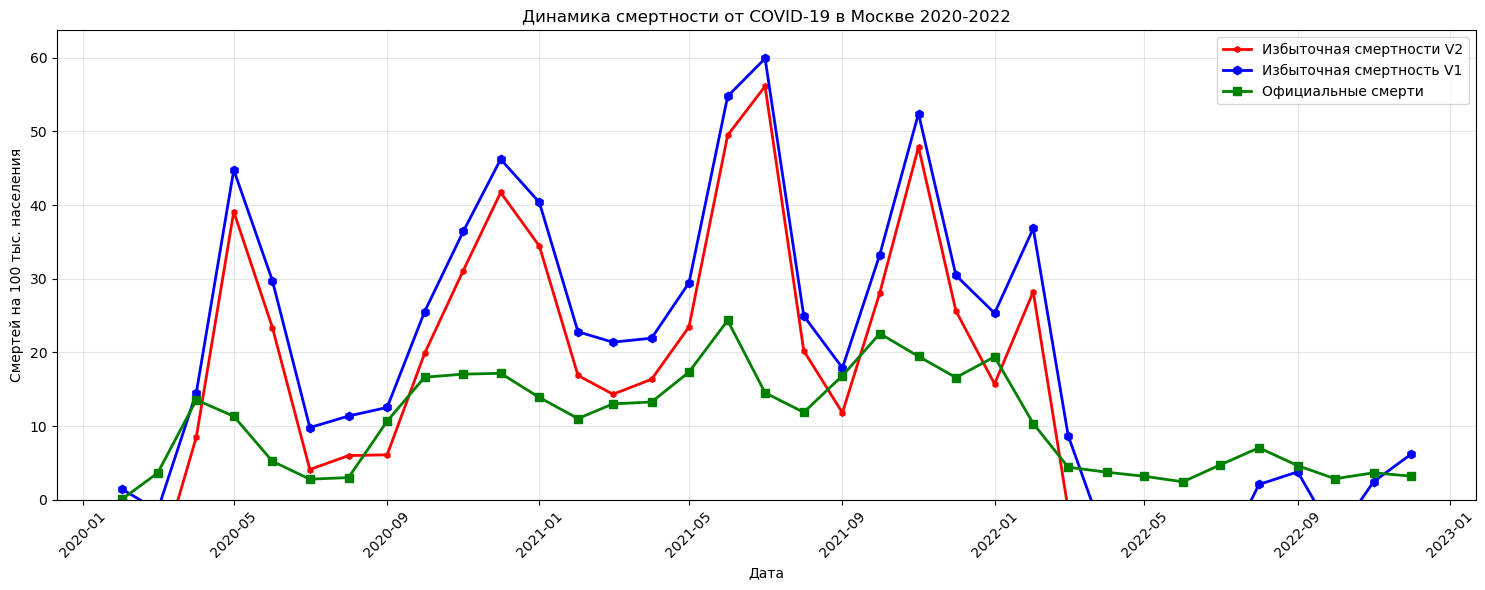

In [35]:
plt.figure(figsize=(15, 6))
plt.plot(covid_cummaulative_mortality['date'], covid_cummaulative_mortality['death_per_100k_V2'], color='red', marker='h', linewidth=2, markersize=4, label='Избыточная смертности V2')
plt.plot(covid_cummaulative_mortality['date'], covid_cummaulative_mortality['calculated_death_per_100k'], color='blue', marker='h', linewidth=2, label='Избыточная смертность V1')
plt.plot(covid_cummaulative_mortality['date'], covid_cummaulative_mortality['officcial_death_per_100k'], color='green', marker='s', linewidth=2, label='Официальные смерти')
plt.xlabel('Дата')
plt.ylabel('Смертей на 100 тыс. населения')
plt.title('Динамика смертности от COVID-19 в Москве 2020-2022')
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.ylim(bottom=0)
plt.tight_layout()
plt.show()

# Помесячная статистика

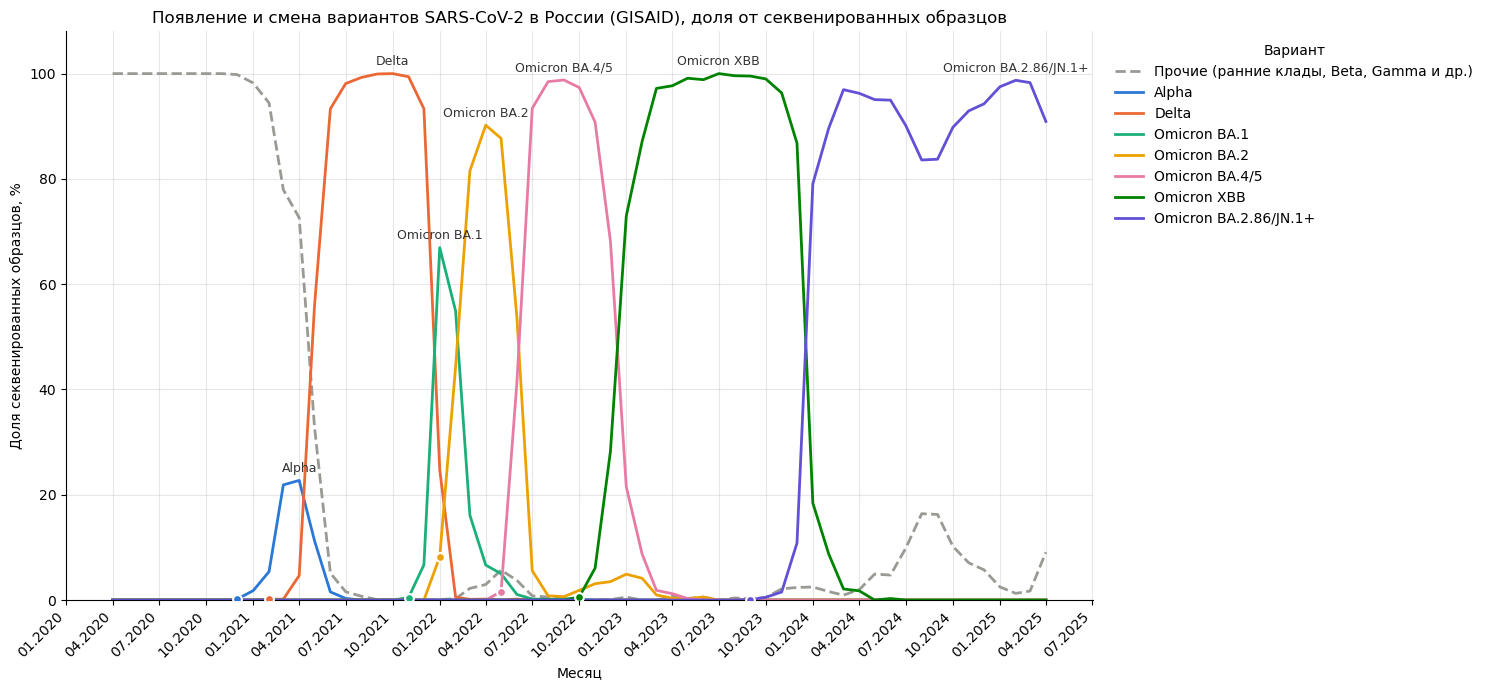

In [24]:
df_russian_variants = pd.read_csv('../covid_19_statistic/gisaid/russia_variants_monthly_share.csv', sep=';', decimal=',')

df_plot = df_russian_variants.copy()
df_plot['date'] = pd.to_datetime(df_plot[['year', 'month']].assign(day=1))
df_plot = df_plot.set_index('date')

main_variants = {
    'Alpha':                 '#2a78d6',
    'Delta':                 '#eb6834',
    'Omicron BA.1':          '#1baf7a',
    'Omicron BA.2':          '#eda100',
    'Omicron BA.4/5':        '#e87ba4',
    'Omicron XBB':           '#008300',
    'Omicron BA.2.86/JN.1+': '#6250d6',
}
variant_cols = df_plot.columns.drop(['year', 'month', 'total_sequences'])
df_plot[variant_cols] = df_plot[variant_cols].apply(pd.to_numeric, errors='coerce').fillna(0)
minor_cols = [c for c in variant_cols if c not in main_variants]
df_plot['Прочие'] = df_plot[minor_cols].sum(axis=1)

fig, ax = plt.subplots(figsize=(15, 7))

ax.plot(df_plot.index, df_plot['Прочие'] * 100, color='#9a9a94', linewidth=2,
        linestyle='--', label='Прочие (ранние клады, Beta, Gamma и др.)')

for variant, color in main_variants.items():
    share = df_plot[variant] * 100
    ax.plot(share.index, share, color=color, linewidth=2, label=variant)

    peak_date = share.idxmax()
    ax.annotate(variant, (peak_date, share.max()), xytext=(0, 6), textcoords='offset points',
                ha='center', fontsize=9, color='#333333')

    first_date = share[share > 0].index.min()
    ax.scatter(first_date, share[first_date], color=color, s=40, zorder=3,
               edgecolor='white', linewidth=1.5)

ax.set_title('Появление и смена вариантов SARS-CoV-2 в России (GISAID), доля от секвенированных образцов')
ax.set_xlabel('Месяц')
ax.set_ylabel('Доля секвенированных образцов, %')
ax.set_ylim(0, 108)
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%m.%Y'))
plt.setp(ax.get_xticklabels(), rotation=45, ha='right')
ax.grid(True, alpha=0.3)
for side in ['top', 'right']:
    ax.spines[side].set_visible(False)
ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1), frameon=False, title='Вариант')

plt.tight_layout()
plt.show()


In [ ]:
main_variants = {
    'Alpha':                 '#2a78d6',
    'Delta':                 '#eb6834',
    'Omicron BA.1':          '#1baf7a',
    'Omicron BA.2':          '#eda100',
    'Omicron BA.4/5':        '#e87ba4',
    'Omicron XBB':           '#008300',
    'Omicron BA.2.86/JN.1+': '#6250d6',
}

df_biweekly = pd.read_csv('../covid_19_statistic/gisaid/russia_variants_biweekly_clades.csv', sep=';', decimal=',', parse_dates=['week'])
total_bw = df_biweekly.groupby('week')['total_sequences'].first()
df_bw_share = (df_biweekly.pivot_table(index='week', columns='variant', values='n', aggfunc='sum')
               [list(main_variants)].div(total_bw, axis=0))
df_clade = (df_biweekly.pivot_table(index='week', columns='clade', values='n', aggfunc='sum')
            .div(total_bw, axis=0).fillna(0))
clade_variant = df_biweekly.drop_duplicates('clade').set_index('clade')['variant']

minor_clades = clade_variant[~clade_variant.isin(main_variants)].index
df_minor = df_clade[minor_clades]

with open('../covid_19_statistic/gisaid/gisaid_variants_statistics_2026_11_08_0505/gisaid_variants_statistics.json') as f:
    gisaid_stats = json.load(f)['stats']

df_gisaid = pd.DataFrame([
    {'date': pd.Timestamp(week), 'clade': row['value'], 'n': row['count']}
    for week, countries in gisaid_stats.items() if 'Russia' in countries
    for row in countries['Russia']['submissions_per_clade']
])
df_gisaid = df_gisaid[~df_gisaid['clade'].isin(['GRY', 'GK', 'GRA'])]

periods = df_clade.index
pos = periods.searchsorted(df_gisaid['date'], side='right') - 1
in_range = (pos >= 0) & (df_gisaid['date'] < periods[-1] + pd.Timedelta(days=14))
df_gisaid = df_gisaid[in_range].assign(week=periods[pos[in_range]])

gisaid_share = (df_gisaid.pivot_table(index='week', columns='clade', values='n', aggfunc='sum')
                .reindex(periods).fillna(0))
gisaid_share = gisaid_share.div(gisaid_share.sum(axis=1), axis=0).fillna(0)

residual = (1 - df_bw_share.sum(axis=1) - df_minor.sum(axis=1)).clip(lower=0)
df_early = gisaid_share.mul(residual, axis=0)
df_early['не определена'] = residual.where(gisaid_share.sum(axis=1) == 0, 0)

gisaid_names = {
    'L': 'L (исходная линия, Ухань)', 'S': 'S (A.*)', 'V': 'V (B.2)', 'G': 'G (B.1, D614G)',
    'GH': 'GH (B.1.*)', 'GR': 'GR (B.1.1.*)', 'GV': 'GV (B.1.177)', 'O': 'O (прочие по GISAID)',
}
df_others = pd.concat([df_early.rename(columns=gisaid_names),
                       df_minor.rename(columns={'recombinant': 'рекомбинанты (recombinant)'})], axis=1)

named_clades = clade_variant[~clade_variant.isin(main_variants)
                             & ~clade_variant.str.startswith('Прочие')].index
min_peak = 0.01
rare = df_others.columns[(df_others.max() < min_peak) & ~df_others.columns.isin(named_clades)]
rare_sum = df_others[rare].sum(axis=1)
df_others = df_others.drop(columns=rare)
if len(rare):
    df_others[f'редкие клады (< {min_peak:.0%} на пике)'] = rare_sum

first_seen = (df_others > 0).idxmax()
df_others = df_others[first_seen.sort_values(kind='stable').index]

other_palette = ['#bab0ac', '#9d755d', '#c9b28f', '#8f8f86', '#b5a7c4', '#a7bfb8',
                 '#d4a6a6', '#7f7f9c', '#c4c48a', '#9cb1c9', '#d9c3b0', '#6f6a5e',
                 '#a3c4a8', '#c9a3b5', '#8fa3a3']


def plot_variants_stack(variant_groups, title):
    """
    Накопительный график: клады из df_others внизу, основные варианты сверху
    """
    df_groups = pd.DataFrame({group: df_bw_share[variants].sum(axis=1)
                              for group, (variants, _) in variant_groups.items()})
    layers = pd.concat([df_others, df_groups], axis=1) * 100
    colors = other_palette[:df_others.shape[1]] + [color for _, color in variant_groups.values()]

    fig, ax = plt.subplots(figsize=(16, 8))
    ax.stackplot(layers.index, layers.T.values, colors=colors, labels=layers.columns,
                 edgecolor='white', linewidth=0.4)

    for name in layers.columns:
        dominant = layers.index[layers[name] > 50]
        if len(dominant) == 0:
            continue
        mid = dominant[0] + (dominant[-1] - dominant[0]) / 2
        bottom = layers.loc[:, :name].iloc[:, :-1].sum(axis=1)
        y = bottom.asof(mid) + layers[name].asof(mid) / 2
        label = name.replace(' (', '\n(') if '(' in name else name.replace('Omicron ', 'Omicron\n')
        ax.annotate(label, (mid, y), ha='center', va='center', fontsize=9, fontweight='bold',
                    color='white' if name in variant_groups else '#333333')

    ax.set_title(title)
    ax.set_ylabel('Доля секвенированных образцов, %')
    ax.set_xlabel('Дата (начало двухнедельного периода)')
    ax.set_ylim(0, 100)
    ax.set_xlim(layers.index.min(), layers.index.max())

    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%d.%m.%Y'))
    ax.xaxis.set_minor_locator(mdates.MonthLocator())
    plt.setp(ax.get_xticklabels(), rotation=45, ha='right')
    ax.grid(True, axis='x', which='major', alpha=0.3)
    for side in ['top', 'right']:
        ax.spines[side].set_visible(False)

    ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1), frameon=False, title='Вариант / клада',
              reverse=True, fontsize=9)

    plt.tight_layout()
    plt.show()


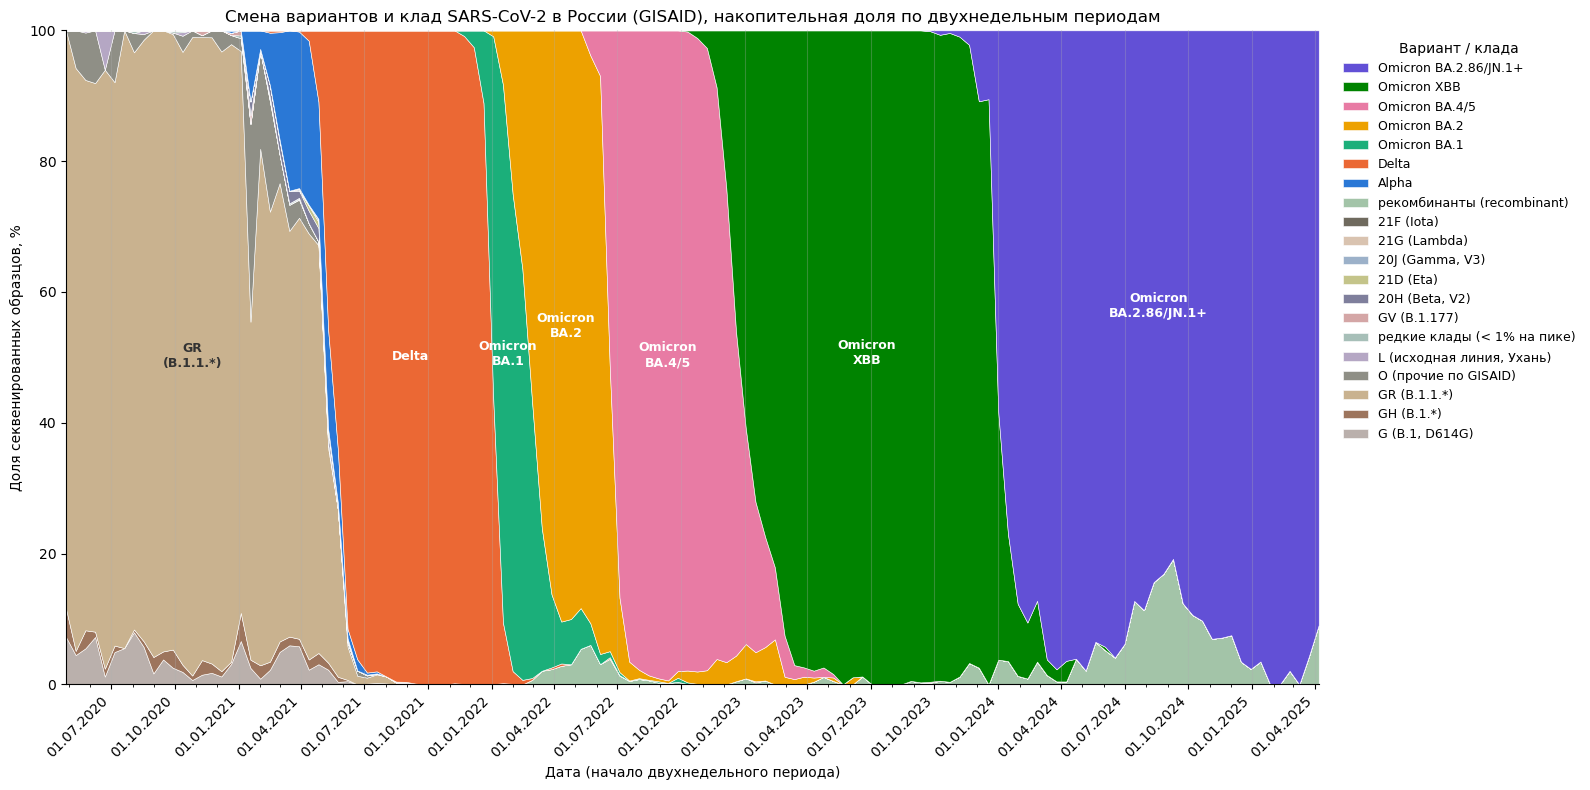

In [30]:
plot_variants_stack(
    {variant: ([variant], color) for variant, color in main_variants.items()},
    'Смена вариантов и клад SARS-CoV-2 в России (GISAID), накопительная доля по двухнедельным периодам'
)

Недель без образцов (заполнены предыдущей неделей): 2


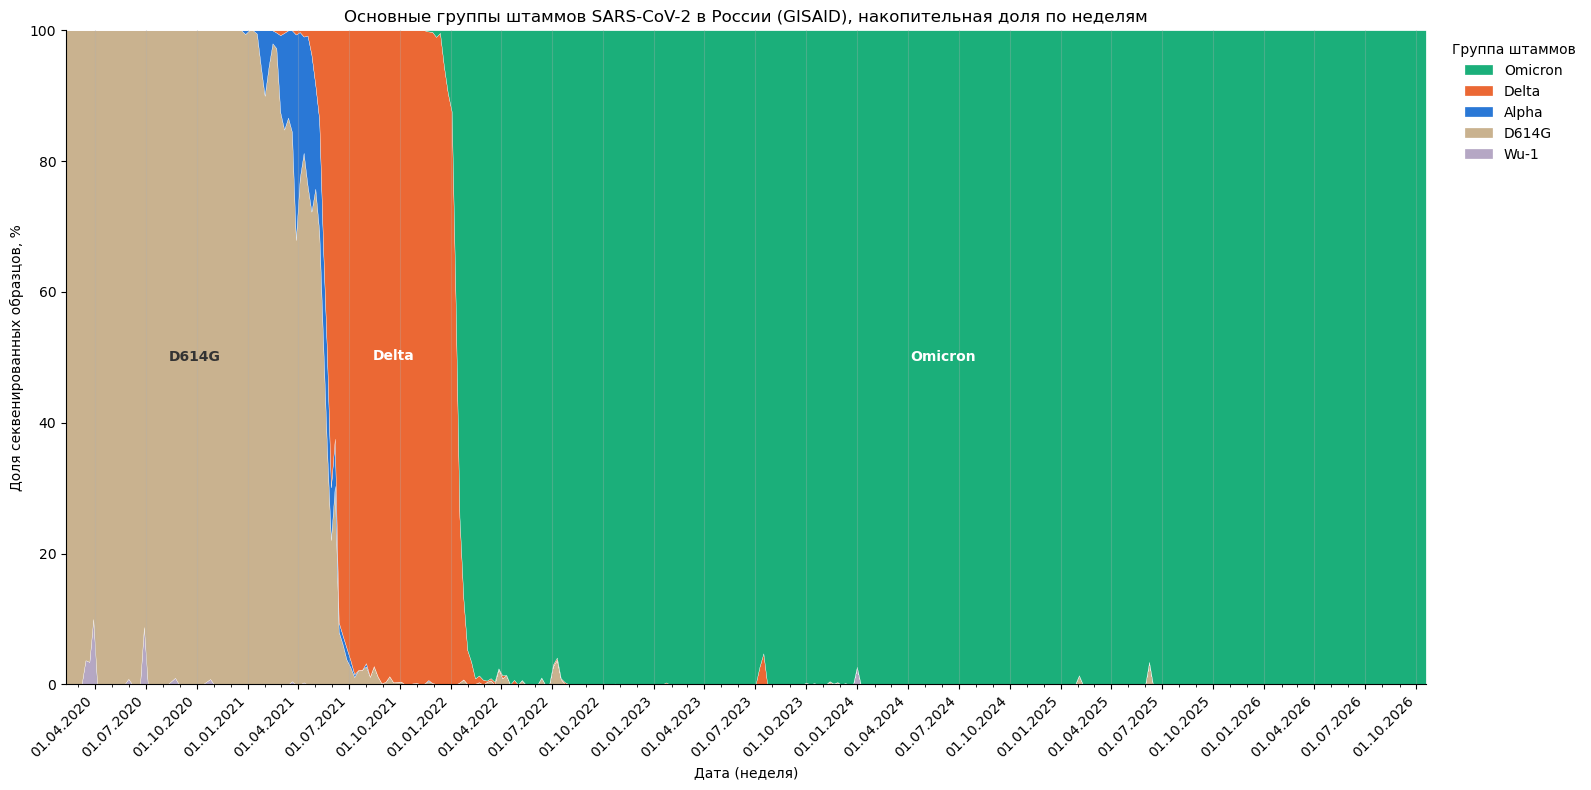

In [32]:
with open('../covid_19_statistic/gisaid/gisaid_variants_statistics_2026_11_08_0505/gisaid_variants_statistics.json') as f:
    gisaid_stats = json.load(f)['stats']


def variant_group(variant):
    """Группа штамма по названию варианта GISAID ('Other' разбирается отдельно по кладам)."""
    if 'Alpha' in variant:
        return 'Alpha'
    if 'Delta' in variant:
        return 'Delta'
    if any(name in variant for name in ['Beta', 'Gamma', 'Eta', 'Iota', 'Kappa', 'Lambda', 'Mu',
                                         'Epsilon', 'Zeta', 'Theta']):
        return 'D614G'
    return 'Omicron'


rows = []
for week, countries in gisaid_stats.items():
    if 'Russia' not in countries:
        continue
    stats = countries['Russia']
    named = {}
    for row in stats['submissions_per_variant']:
        if row['value'] != 'Other':
            group = variant_group(row['value'])
            named[group] = named.get(group, 0) + row['count']
    clades = {row['value']: row['count'] for row in stats['submissions_per_clade']}

    left = sum(r['count'] for r in stats['submissions_per_variant'] if r['value'] == 'Other')
    omicron_extra = clades.get('GRA', 0) - named.get('Omicron', 0) if week >= '2021-11-01' else 0
    delta_extra = clades.get('GK', 0) - named.get('Delta', 0) if week >= '2021-03-01' else 0
    for group, clade_count in [('Wu-1', sum(clades.get(c, 0) for c in ['L', 'S', 'V'])),
                               ('Omicron', omicron_extra),
                               ('Delta', delta_extra)]:
        n = min(left, max(clade_count, 0))
        named[group] = named.get(group, 0) + n
        left -= n
    named['D614G'] = named.get('D614G', 0) + left

    rows += [{'week': week, 'group': group, 'n': n} for group, n in named.items()]

strain_order = ['Wu-1', 'D614G', 'Alpha', 'Delta', 'Omicron']
strain_colors = ['#b5a7c4', '#c9b28f', '#2a78d6', '#eb6834', '#1baf7a']

counts_weekly = (pd.DataFrame(rows).assign(week=lambda df: pd.to_datetime(df['week']))
                 .pivot_table(index='week', columns='group', values='n', aggfunc='sum')
                 .reindex(columns=strain_order, fill_value=0).fillna(0))
counts_weekly = counts_weekly.reindex(pd.date_range(counts_weekly.index.min(), counts_weekly.index.max(), freq='7D'),
                                      fill_value=0)

layers = counts_weekly.div(counts_weekly.sum(axis=1), axis=0).ffill() * 100
no_samples = counts_weekly.index[counts_weekly.sum(axis=1) == 0]
print(f'Недель без образцов (заполнены предыдущей неделей): {len(no_samples)}')

fig, ax = plt.subplots(figsize=(16, 8))
ax.stackplot(layers.index, layers.T.values, colors=strain_colors, labels=layers.columns,
             edgecolor='white', linewidth=0.2)

for name in layers.columns:
    dominant = layers.index[layers[name] > 50]
    if len(dominant) == 0:
        continue
    mid = dominant[0] + (dominant[-1] - dominant[0]) / 2
    bottom = layers.loc[:, :name].iloc[:, :-1].sum(axis=1)
    y = bottom.asof(mid) + layers[name].asof(mid) / 2
    ax.annotate(name, (mid, y), ha='center', va='center', fontsize=10,
                fontweight='bold', color='#333333' if name in ['Wu-1', 'D614G'] else 'white')

ax.set_title('Основные группы штаммов SARS-CoV-2 в России (GISAID), накопительная доля по неделям')
ax.set_ylabel('Доля секвенированных образцов, %')
ax.set_xlabel('Дата (неделя)')
ax.set_ylim(0, 100)
ax.set_xlim(layers.index.min(), layers.index.max())

ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d.%m.%Y'))
ax.xaxis.set_minor_locator(mdates.MonthLocator())
plt.setp(ax.get_xticklabels(), rotation=45, ha='right')
ax.grid(True, axis='x', which='major', alpha=0.3)
for side in ['top', 'right']:
    ax.spines[side].set_visible(False)

ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1), frameon=False, title='Группа штаммов', reverse=True)

plt.tight_layout()
plt.show()


In [42]:
continuous_df['date'] = pd.to_datetime(continuous_df['date'])
filtered_df['date'] = pd.to_datetime(filtered_df['date'])

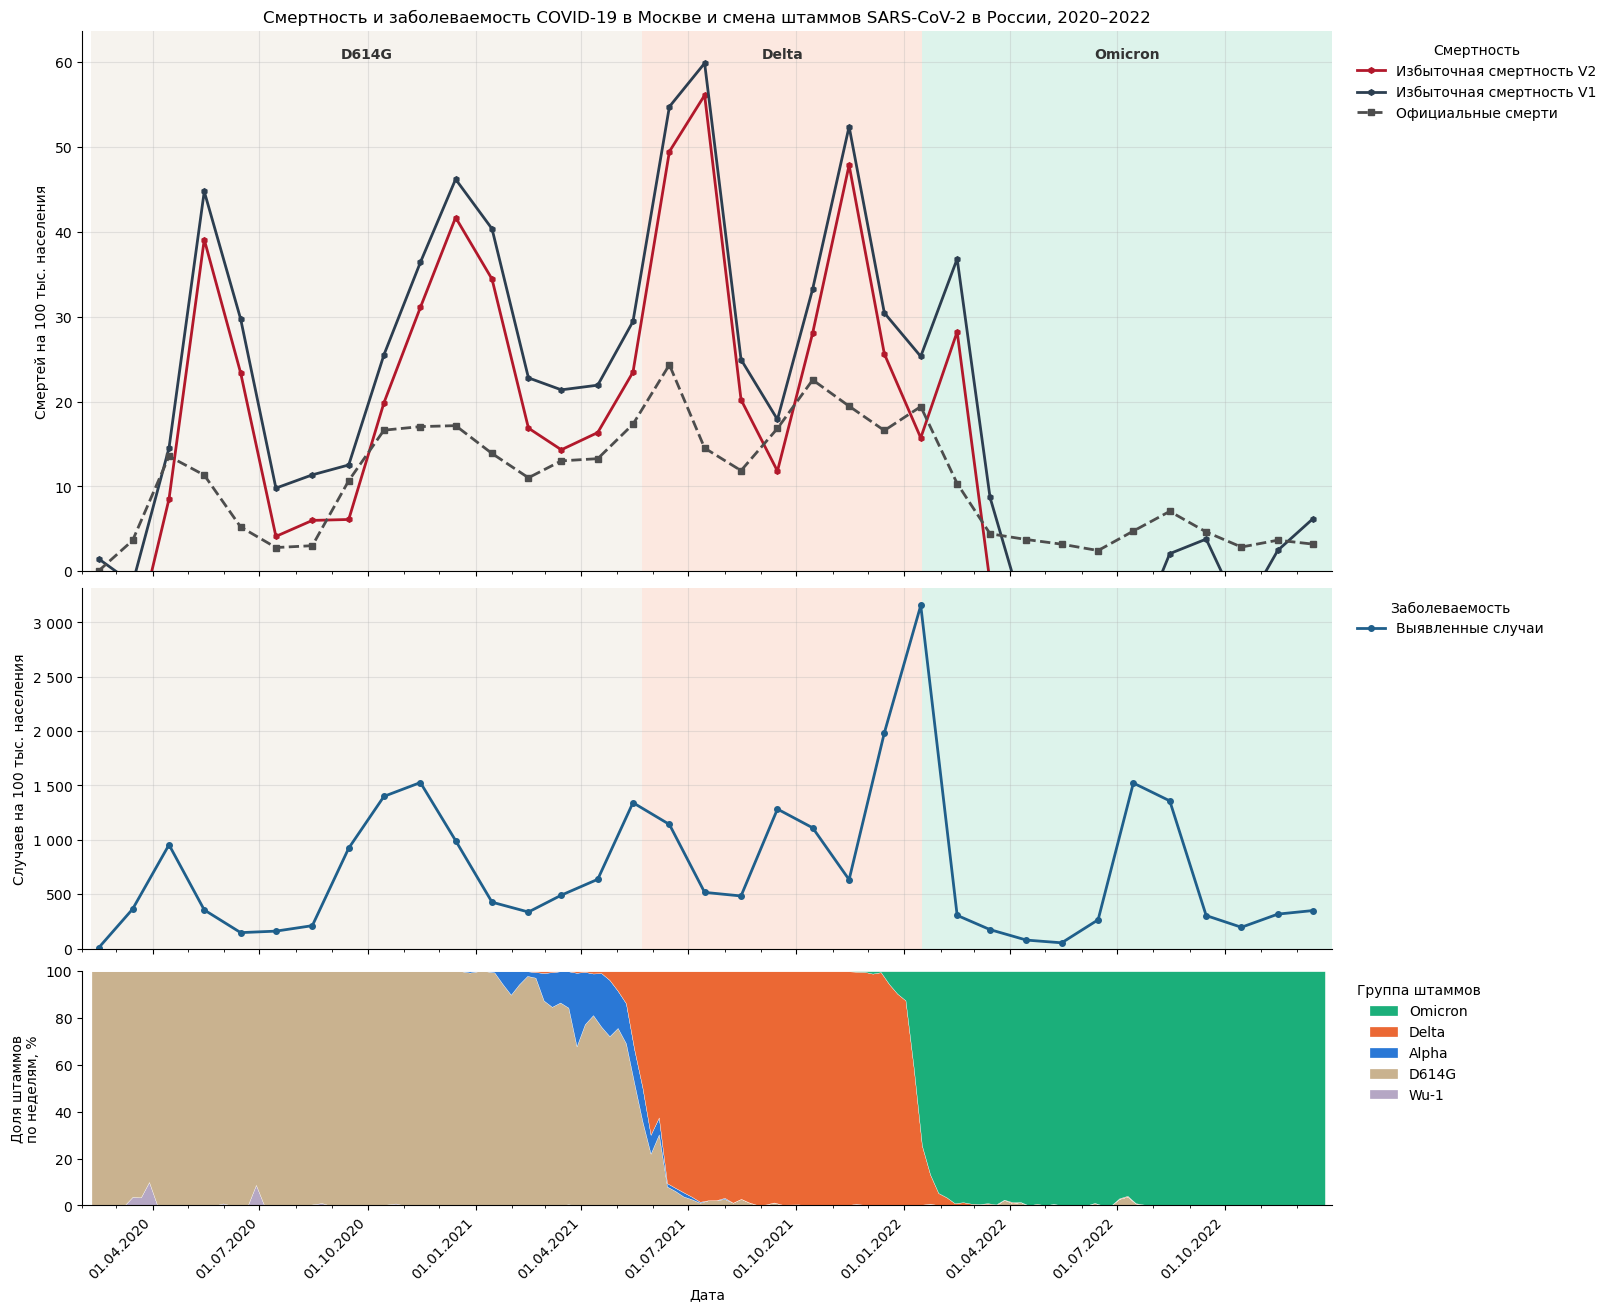

In [43]:
# Смертность и заболеваемость в Москве на фоне смены штаммов SARS-CoV-2 в России
# Панели: 1) смертность, 2) заболеваемость, 3) доли групп штаммов (график 3).
# Фон верхних панелей — группа штаммов с наибольшей долей в периоде
period_start, period_end = pd.Timestamp('2020-02-01'), pd.Timestamp('2022-12-31')
shares = layers.loc[period_start:period_end]
group_colors = dict(zip(layers.columns, strain_colors))

# Смертность и заболеваемость есть только помесячно — ставим их на середину месяца
mid_month = pd.Timedelta(days=14)

fig, (ax_d, ax_c, ax_s) = plt.subplots(3, 1, figsize=(16, 13), sharex=True, layout='constrained',
                                       gridspec_kw={'height_ratios': [3, 2, 1.3]})

# Фон: группа с наибольшей долей в каждой неделе; подписываем только периоды от 4 недель
dominant = shares.idxmax(axis=1)
for ax in (ax_d, ax_c):
    for _, segment in dominant.groupby((dominant != dominant.shift()).cumsum()):
        start, end = segment.index[0], segment.index[-1] + pd.Timedelta(days=7)
        name = segment.iloc[0]
        ax.axvspan(start, end, color=group_colors[name], alpha=0.15, linewidth=0)
        if ax is ax_d and len(segment) >= 4:
            ax.text(start + (end - start) / 2, 0.97, name, transform=ax.get_xaxis_transform(),
                    ha='center', va='top', fontsize=10, fontweight='bold', color='#333333')

# 1. Смертность
ax_d.plot(continuous_df['date'] + mid_month, continuous_df['death_per_100k_V2'], color='#b2182b',
          marker='h', linewidth=2, markersize=4, label='Избыточная смертность V2')
ax_d.plot(filtered_df['date'] + mid_month, filtered_df['calculated_death_per_100k'], color='#2c3e50',
          marker='h', linewidth=2, markersize=4, label='Избыточная смертность V1')
ax_d.plot(filtered_df['date'] + mid_month, filtered_df['officcial_death_per_100k'], color='#4d4d4d',
          marker='s', linewidth=2, markersize=4, linestyle='--', label='Официальные смерти')
ax_d.set_title('Смертность и заболеваемость COVID-19 в Москве и смена штаммов SARS-CoV-2 в России, 2020–2022')
ax_d.set_ylabel('Смертей на 100 тыс. населения')
ax_d.set_ylim(bottom=0)  # отрицательная избыточная смертность (2022) уходит за нижний край
ax_d.legend(loc='upper left', bbox_to_anchor=(1.01, 1), frameon=False, title='Смертность')

# 2. Заболеваемость
ax_c.plot(filtered_df['date'] + mid_month, filtered_df['cases_per_100k'], color='#1f5f8b',
          marker='o', linewidth=2, markersize=4, label='Выявленные случаи')
ax_c.set_ylabel('Случаев на 100 тыс. населения')
ax_c.set_ylim(bottom=0)
ax_c.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:,.0f}'.replace(',', ' ')))
ax_c.legend(loc='upper left', bbox_to_anchor=(1.01, 1), frameon=False, title='Заболеваемость')

# 3. Доли групп штаммов по неделям
ax_s.stackplot(shares.index, shares.T.values, colors=strain_colors, labels=shares.columns,
               edgecolor='white', linewidth=0.2)
ax_s.set_ylabel('Доля штаммов\nпо неделям, %')
ax_s.set_ylim(0, 100)
ax_s.set_xlabel('Дата')
ax_s.legend(loc='upper left', bbox_to_anchor=(1.01, 1), frameon=False, title='Группа штаммов', reverse=True)

ax_s.set_xlim(period_start, period_end)
ax_s.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
ax_s.xaxis.set_major_formatter(mdates.DateFormatter('%d.%m.%Y'))
ax_s.xaxis.set_minor_locator(mdates.MonthLocator())
plt.setp(ax_s.get_xticklabels(), rotation=45, ha='right')
for ax in (ax_d, ax_c, ax_s):
    for side in ['top', 'right']:
        ax.spines[side].set_visible(False)
for ax in (ax_d, ax_c):
    ax.grid(True, alpha=0.3)

plt.show()


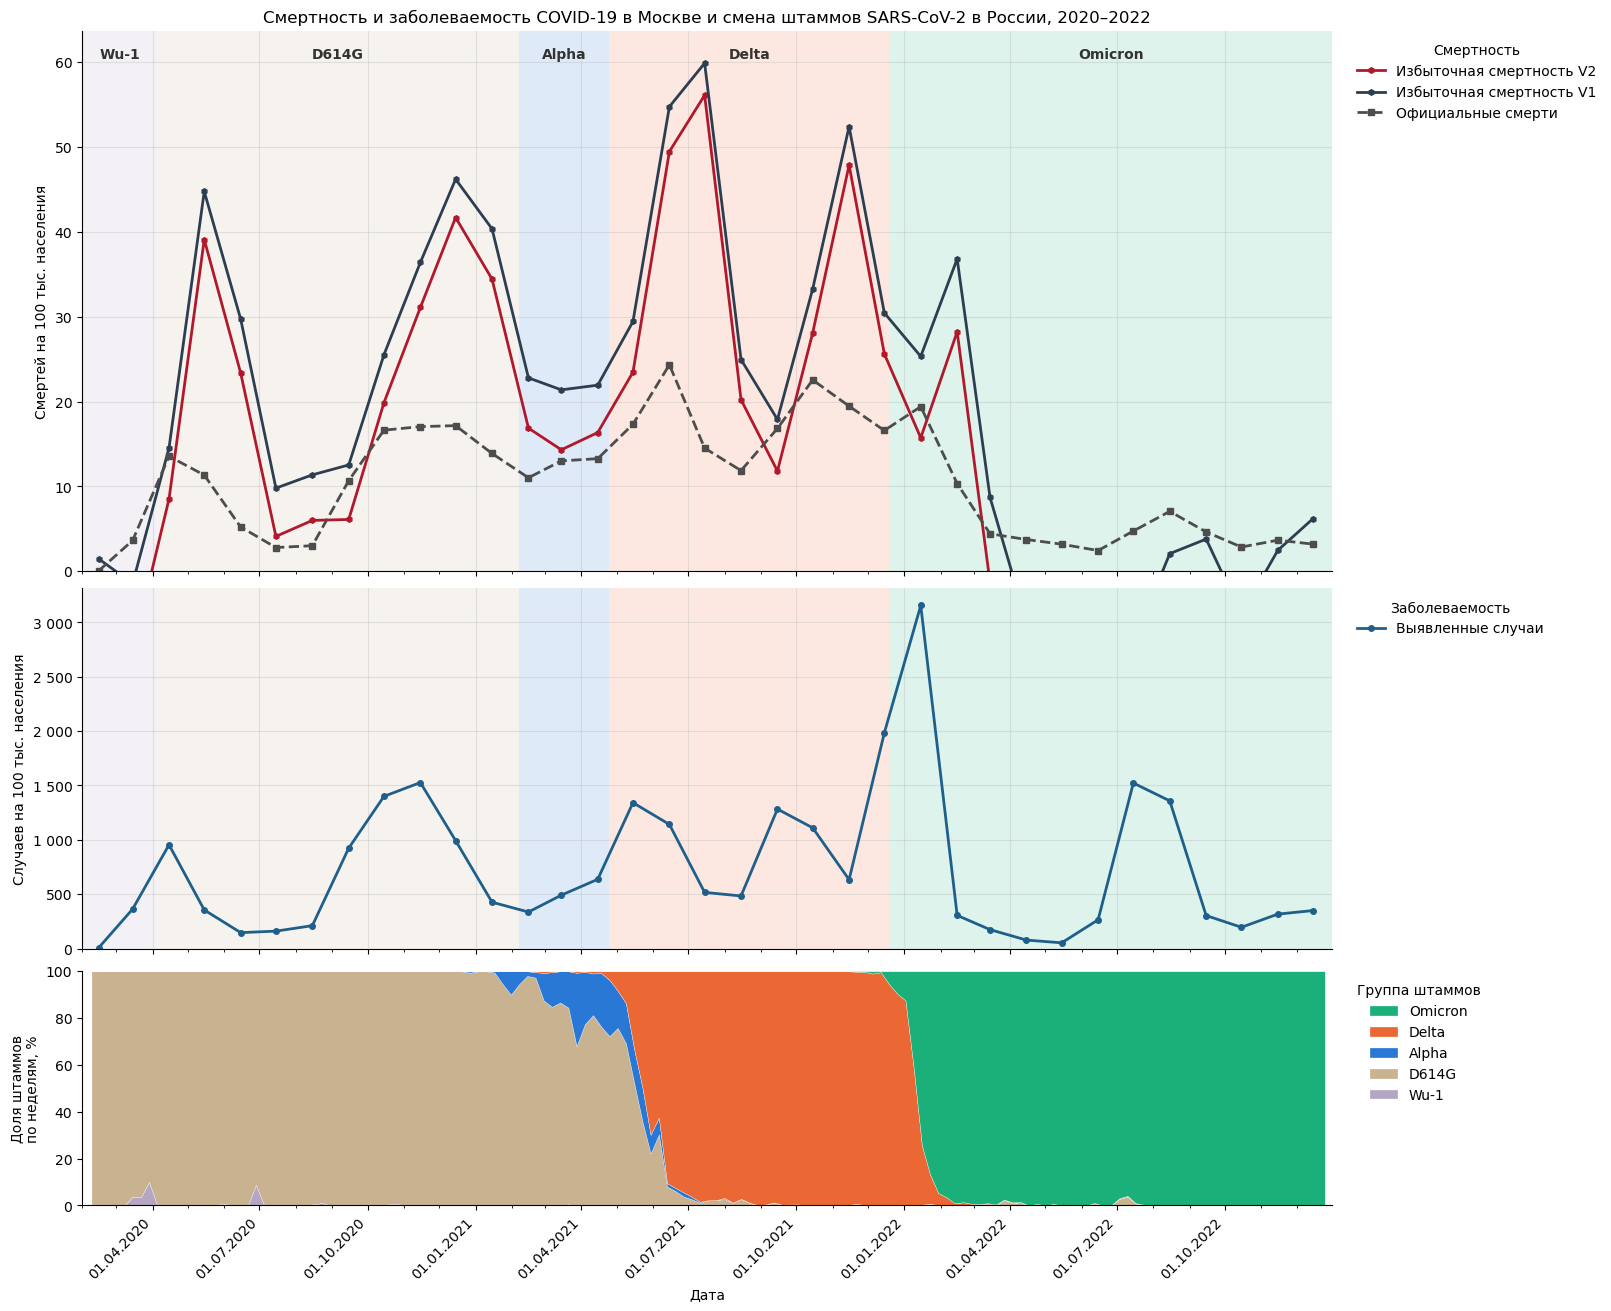

In [45]:
# Смертность и заболеваемость в Москве на фоне смены штаммов SARS-CoV-2 в России
# Панели: 1) смертность, 2) заболеваемость, 3) доли групп штаммов (график 3).
# Фон верхних панелей — группа штаммов с наибольшей долей в периоде
period_start, period_end = pd.Timestamp('2020-02-01'), pd.Timestamp('2022-12-31')
shares = layers.loc[period_start:period_end]
group_colors = dict(zip(layers.columns, strain_colors))

# Смертность и заболеваемость есть только помесячно — ставим их на середину месяца
mid_month = pd.Timedelta(days=14)

fig, (ax_d, ax_c, ax_s) = plt.subplots(3, 1, figsize=(16, 13), sharex=True, layout='constrained',
                                       gridspec_kw={'height_ratios': [3, 2, 1.3]})

# Фон: самая новая группа, чья доля (сглаженная по 5 неделям) не ниже 5% — так на фоне появляется
# Alpha (максимум 31%, лидером по доле не бывает). Wu-1 в выборке GISAID редок (максимум 10%),
# поэтому закреплён за началом пандемии, до распространения D614G. Подписываем периоды от 4 недель
bg_threshold, wu1_end = 5, pd.Timestamp('2020-04-01')
smooth = shares.rolling(5, center=True, min_periods=1).mean()
passed = smooth.ge(bg_threshold)
dominant = passed.iloc[:, ::-1].idxmax(axis=1).where(passed.any(axis=1), shares.idxmax(axis=1))
dominant[dominant.index < wu1_end] = 'Wu-1'
for ax in (ax_d, ax_c):
    for _, segment in dominant.groupby((dominant != dominant.shift()).cumsum()):
        start = period_start if segment.index[0] == dominant.index[0] else segment.index[0]
        end = segment.index[-1] + pd.Timedelta(days=7)
        name = segment.iloc[0]
        ax.axvspan(start, end, color=group_colors[name], alpha=0.15, linewidth=0)
        if ax is ax_d and (end - start).days >= 28:
            ax.text(start + (end - start) / 2, 0.97, name, transform=ax.get_xaxis_transform(),
                    ha='center', va='top', fontsize=10, fontweight='bold', color='#333333')

# 1. Смертность
ax_d.plot(continuous_df['date'] + mid_month, continuous_df['death_per_100k_V2'], color='#b2182b',
          marker='h', linewidth=2, markersize=4, label='Избыточная смертность V2')
ax_d.plot(filtered_df['date'] + mid_month, filtered_df['calculated_death_per_100k'], color='#2c3e50',
          marker='h', linewidth=2, markersize=4, label='Избыточная смертность V1')
ax_d.plot(filtered_df['date'] + mid_month, filtered_df['officcial_death_per_100k'], color='#4d4d4d',
          marker='s', linewidth=2, markersize=4, linestyle='--', label='Официальные смерти')
ax_d.set_title('Смертность и заболеваемость COVID-19 в Москве и смена штаммов SARS-CoV-2 в России, 2020–2022')
ax_d.set_ylabel('Смертей на 100 тыс. населения')
ax_d.set_ylim(bottom=0)  # отрицательная избыточная смертность (2022) уходит за нижний край
ax_d.legend(loc='upper left', bbox_to_anchor=(1.01, 1), frameon=False, title='Смертность')

# 2. Заболеваемость
ax_c.plot(filtered_df['date'] + mid_month, filtered_df['cases_per_100k'], color='#1f5f8b',
          marker='o', linewidth=2, markersize=4, label='Выявленные случаи')
ax_c.set_ylabel('Случаев на 100 тыс. населения')
ax_c.set_ylim(bottom=0)
ax_c.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:,.0f}'.replace(',', ' ')))
ax_c.legend(loc='upper left', bbox_to_anchor=(1.01, 1), frameon=False, title='Заболеваемость')

# 3. Доли групп штаммов по неделям
ax_s.stackplot(shares.index, shares.T.values, colors=strain_colors,
               labels=shares.columns,
               edgecolor='white', linewidth=0.2)
ax_s.set_ylabel('Доля штаммов\nпо неделям, %')
ax_s.set_ylim(0, 100)
ax_s.set_xlabel('Дата')
ax_s.legend(loc='upper left', bbox_to_anchor=(1.01, 1), frameon=False, title='Группа штаммов', reverse=True)

ax_s.set_xlim(period_start, period_end)
ax_s.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
ax_s.xaxis.set_major_formatter(mdates.DateFormatter('%d.%m.%Y'))
ax_s.xaxis.set_minor_locator(mdates.MonthLocator())
plt.setp(ax_s.get_xticklabels(), rotation=45, ha='right')
for ax in (ax_d, ax_c, ax_s):
    for side in ['top', 'right']:
        ax.spines[side].set_visible(False)
for ax in (ax_d, ax_c):
    ax.grid(True, alpha=0.3)

plt.show()
